# 06 - Evaluation, SHAP, rolling-origin, error analysis (Member 5)

The test period (Jul 2025 to Jul 2026) is evaluated **once**, after the model and threshold were fixed on validation (`src/evaluate.py: final_test_evaluation` refuses a second run). Plan: `docs/evaluation_plan.md`.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
OUT = ROOT / "reports" / "review1" / "m5"
if not (OUT / "results.json").exists():
    raise SystemExit("Run the modelling first:  python -m src.run_models   (needs data/processed/questions_clean_v1.parquet)")
R = json.loads((OUT / "results.json").read_text())
pd.set_option("display.width", 150, "display.max_columns", 30)
def table(name, **kw):
    return pd.read_csv(OUT / name, **kw)


## Final test evaluation (M5-10)

model,xgboost
n,16695.0000
positive_rate,0.2969
threshold,0.3669
precision,0.3626
recall,0.7712
f1,0.4933
pr_auc,0.4315
roc_auc,0.6548
capture_rate_20,0.2415


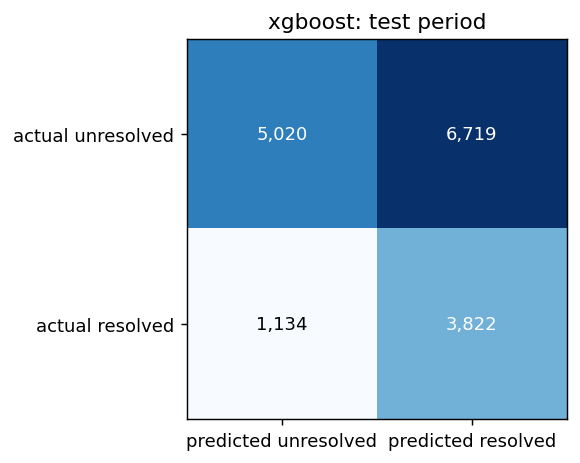

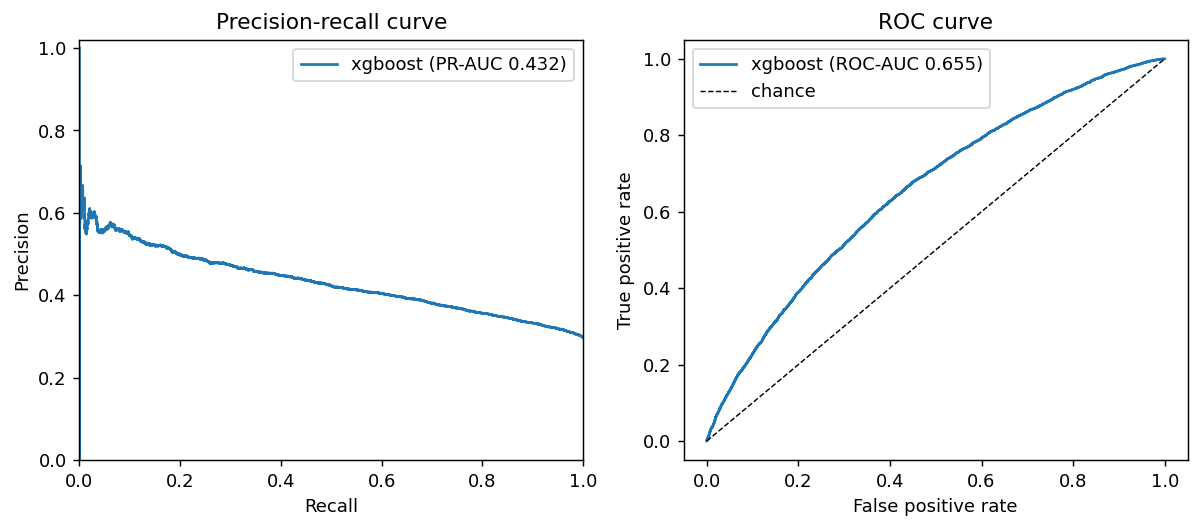

**Capture rate:** flagging the 20% of test questions with the lowest predicted resolution captures **24.1%** of the 11,739 unresolved questions (random flagging: 20%, lift 1.21x). Test size: 16,695.

In [2]:
t = table("test_metrics.csv", index_col=0)
display(t.T)
display(Image(OUT / "test_confusion.png"))
display(Image(OUT / "test_pr_roc.png"))
display(Markdown(f"**Capture rate:** flagging the 20% of test questions with the lowest predicted resolution captures **{R['test']['capture_rate_20']:.1%}** of the {R['test']['n_unresolved']:,} unresolved questions (random flagging: 20%, lift {R['test']['lift_20']:.2f}x). Test size: {int(R['test']['n']):,}."))

## SHAP interpretation (M5-11)
Summary plot and dependence plots for the top 5 features. A positive SHAP value pushes a question towards *resolved*.

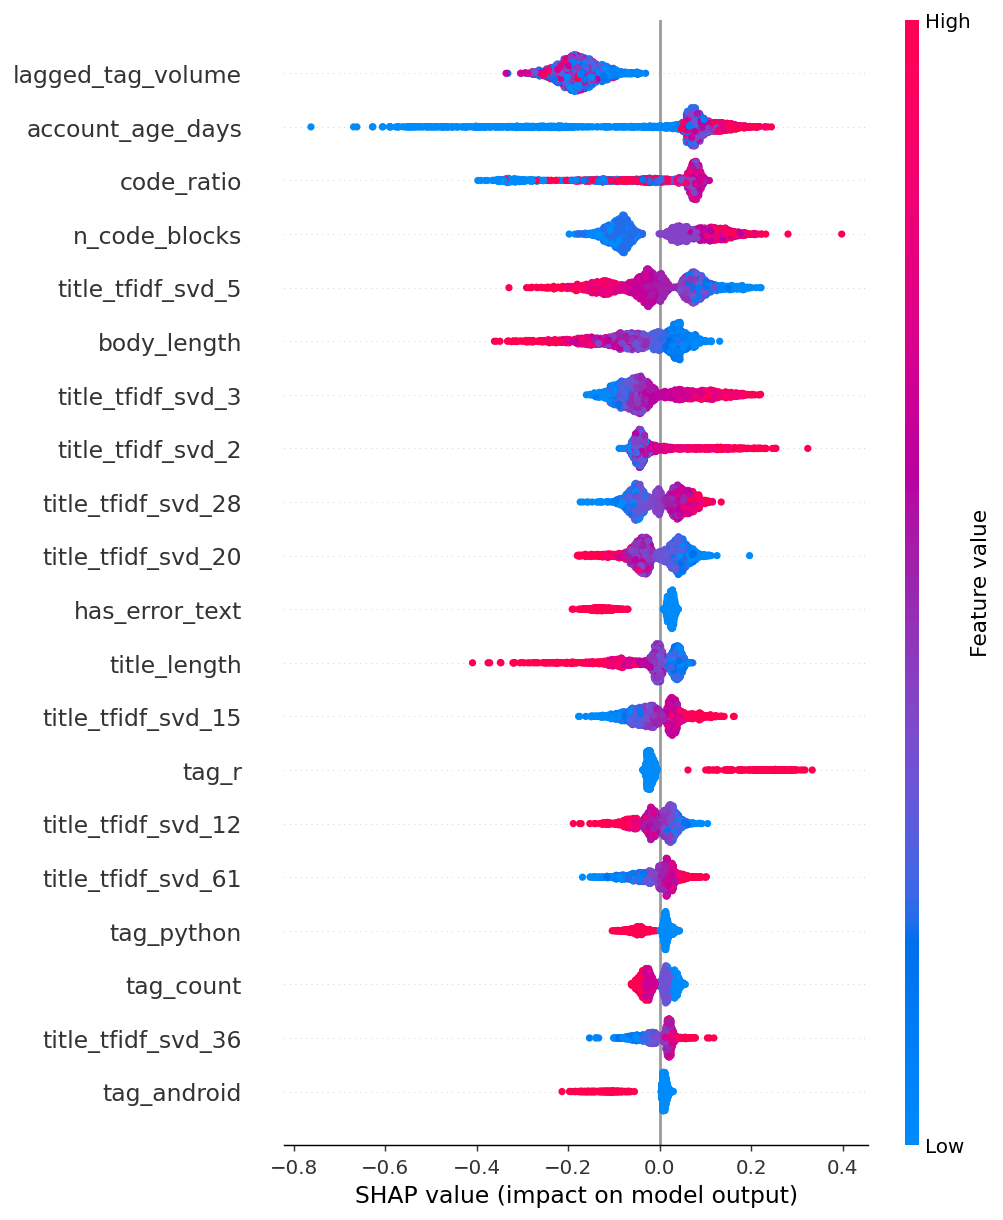

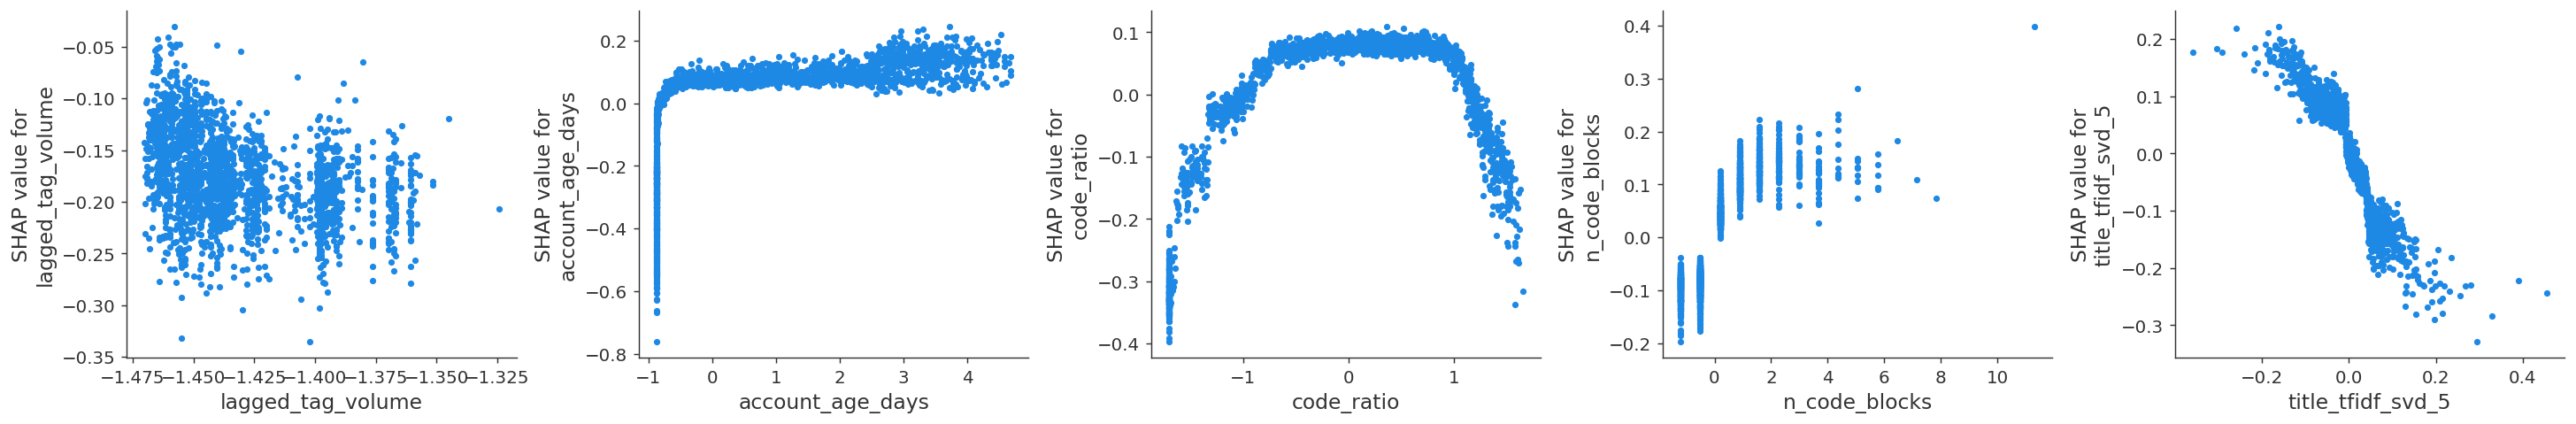

- **lagged_tag_volume**: higher value -> less likely resolved

- **account_age_days**: higher value -> more likely resolved

- **code_ratio**: higher value -> more likely resolved

- **n_code_blocks**: higher value -> more likely resolved

- **title_tfidf_svd_5**: higher value -> less likely resolved

**Reading the plots:**

- Brand-new accounts and questions with no code blocks are the least often resolved; the effect levels off for older accounts.
- Resolution rises with some code, then falls again for questions that are almost all code.
- Error text, longer titles and longer bodies are associated with fewer accepted answers in the test period; the r tag with more, python and android with fewer.
- Tag volume stays in one narrow, low range in the test period (volume has fallen since 2022), so it stands in for the period and tag mix, not for the question itself.

In [3]:
notes = (OUT / "shap_notes.txt").read_text().splitlines() if (OUT / "shap_notes.txt").exists() else []
if (OUT / "shap_summary.png").exists():
    display(Image(OUT / "shap_summary.png"))
    display(Image(OUT / "shap_dependence.png"))
    for f, text in R["shap_direction"].items():
        display(Markdown(f"- **{f}**: {text}"))
    display(Markdown("**Reading the plots:**\n\n" + "\n".join(f"- {n}" for n in notes)))
else:
    print("The chosen model is not tree-based; see logreg_coefficients.csv")

## Rolling-origin evaluation and pre/post-AI comparison (M5-12)
Train on all data before each half-year (minus a 7-day gap) and test on that half-year, 2021 H1 to 2026 H1. Wording: associated with, never caused by.

,n_train,n,positive_rate,pr_auc,f1,roc_auc,threshold
window,,,,,,,
2021 H1,104490,28831.0,0.4402,0.5660,0.6200,0.6331,0.3418
2021 H2,133483,24892.0,0.4317,0.5588,0.6129,0.6349,0.3758
2022 H1,158164,24821.0,0.4091,0.5545,0.5939,0.6476,0.3607
2022 H2,182477,21754.0,0.4066,0.5557,0.5849,0.6432,0.4161
2023 H1,205443,16763.0,0.3684,0.5092,0.5549,0.6447,0.4090
2023 H2,222176,11473.0,0.3482,0.4854,0.5380,0.6435,0.3972
2024 H1,233784,8809.0,0.3480,0.4865,0.5401,0.6449,0.3535
2024 H2,242777,5358.0,0.3396,0.4863,0.5259,0.6404,0.3393
2025 H1,248137,28132.0,0.3405,0.4820,0.5282,0.6452,0.3529


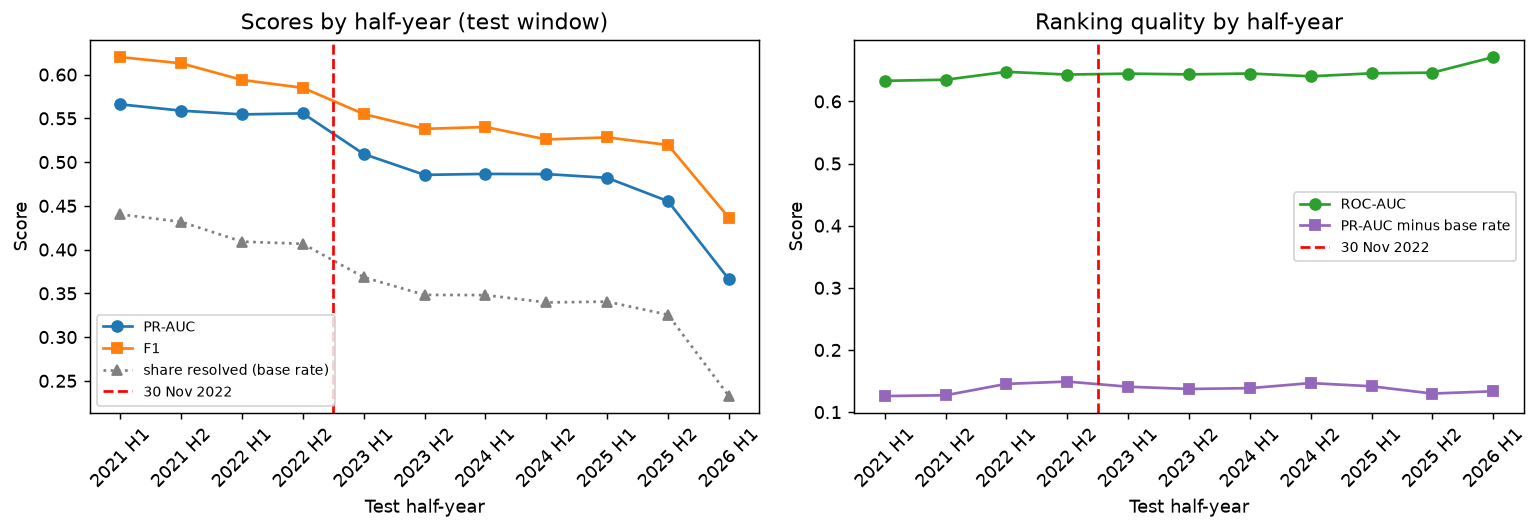

**Takeaway:** ranking quality is stable (mean ROC-AUC 0.640 before 30 Nov 2022, 0.648 after). Mean PR-AUC falls from 0.559 to 0.467, but the share of resolved questions also falls from 0.422 to 0.329; PR-AUC minus that share is 0.137 before and 0.138 after. The fall in PR-AUC follows the fall in the resolution rate, not a loss of ranking skill. This is associated with, not proof of, a change after the break.

Top SHAP features (rank) in one pre-AI and one post-AI window:

,2021 H2,2025 H2
code_ratio,1.0,3.0
account_age_days,2.0,2.0
n_code_blocks,3.0,4.0
title_tfidf_svd_2,4.0,5.0
title_tfidf_svd_5,5.0,NaN
lagged_tag_volume,NaN,1.0


In [4]:
if "rolling" in R:
    display(table("rolling_origin.csv", index_col=0)[["n_train", "n", "positive_rate", "pr_auc", "f1", "roc_auc", "threshold"]])
    display(Image(OUT / "rolling_origin.png"))
    r = R["rolling"]
    display(Markdown(f"**Takeaway:** ranking quality is stable (mean ROC-AUC {r['roc_auc_pre']:.3f} before 30 Nov 2022, {r['roc_auc_post']:.3f} after). Mean PR-AUC falls from {r['pr_auc_pre']:.3f} to {r['pr_auc_post']:.3f}, but the share of resolved questions also falls from {r['positive_rate_pre']:.3f} to {r['positive_rate_post']:.3f}; PR-AUC minus that share is {r['pr_auc_lift_pre']:.3f} before and {r['pr_auc_lift_post']:.3f} after. The fall in PR-AUC follows the fall in the resolution rate, not a loss of ranking skill. This is associated with, not proof of, a change after the break."))
    if (OUT / "shap_pre_post.csv").exists():
        display(Markdown("Top SHAP features (rank) in one pre-AI and one post-AI window:"))
        display(table("shap_pre_post.csv", index_col=0))

## Secondary target check (M5-13)
The same model settings retrained on `target_answered_7d` (any answer within 7 days).

In [5]:
display(table("secondary_target.csv", index_col=0)[["precision", "recall", "f1", "pr_auc", "roc_auc"]])
if (OUT / "shap_secondary.csv").exists():
    display(table("shap_secondary.csv", index_col=0))

,precision,recall,f1,pr_auc,roc_auc
model,,,,,
main: accepted within 7 days,0.3626,0.7712,0.4933,0.4315,0.6548
secondary: any answer within 7 days,0.7142,0.9999,0.8333,0.8300,0.6670


,accepted (main),any answer (secondary)
lagged_tag_volume,1.0,2.0
account_age_days,2.0,NaN
code_ratio,3.0,NaN
n_code_blocks,4.0,4.0
title_tfidf_svd_5,5.0,3.0
body_length,NaN,1.0
title_tfidf_svd_3,NaN,5.0


## Error analysis (M5-14)
30 confident errors (15 false positives, 15 false negatives) in `error_annotation_sheet.csv`. The `auto_hint` column is a rule-based starting guess; **read each question at its link and write the real reason in `likely_reason`**. Titles only, each linked to the original question (CC BY-SA 4.0).

In [6]:
sheet = table("error_annotation_sheet.csv")
display(sheet[["error_type", "title", "predicted_probability", "actual_outcome", "likely_reason", "evidence"]])
from src import error_analysis as ea
display(Markdown("**Reasons found after reading each question:**"))
display(ea.summarise_reasons(sheet))
display(table("error_rates.csv"))
display(Markdown((OUT / "error_analysis_summary.md").read_text()))

,error_type,title,predicted_probability,actual_outcome,likely_reason,evidence
0,false_positive,Is it possible to pass a method to a function ...,0.516,unresolved,no answer received,niche JavaScript question; 0 answers
1,false_positive,remove items from a list based on multiple cri...,0.606,unresolved,answered but not accepted,"5 answers within minutes, but none accepted; q..."
2,false_positive,Selecting a row with alternatives in R,0.659,unresolved,answered but not accepted,"6 answers (first after 17 min), question score..."
3,false_positive,"Display child of clicked parent, hide other ch...",0.731,unresolved,answered but not accepted,"2 answers, first after about 1 hour; none acce..."
4,false_positive,How to tell Bson to parse an integer values in...,0.560,unresolved,no answer received,niche Java library (BSON) question; 0 answers
5,false_positive,Can I iterate over/get an iterable over multip...,0.606,unresolved,answered but not accepted,3 answers (first after 17 h); question score -...
6,false_positive,"Access object property from a string like ""obj...",0.512,unresolved,answered but not accepted,2 answers within 25 min; a very common kind of...
7,false_positive,Hourly true average between timestamps,0.533,unresolved,no answer received,niche database (GridDB); 0 answers
8,false_positive,Changing Worksheet CodeName in VBA,0.514,unresolved,answered but not accepted,2 answers; none accepted
9,false_positive,List numbering through loop,0.601,unresolved,answered but not accepted,"12 answers, 5,902 views, first answer after 4 ..."


**Reasons found after reading each question:**

error_type,false_negative,false_positive,total
likely_reason,,,
answered but not accepted,0,10,10
new asker account,8,0,8
no answer received,0,4,4
no code block,2,0,2
low-resolution tag with error text,2,0,2
accepted just after the 7-day window,0,1,1
long body and error text,1,0,1
error text not detected,1,0,1
high-visibility question without code,1,0,1


,feature,group,n,errors,error_rate
0,title_length,"(0, 30]",653,326,0.499
1,title_length,"(30, 60]",6458,3234,0.501
2,title_length,"(60, 100]",7417,3465,0.467
3,title_length,"(100, 1000]",2167,828,0.382
4,body_length,"(0, 200]",923,470,0.509
5,body_length,"(200, 600]",7261,3601,0.496
6,body_length,"(600, 1500]",7264,3318,0.457
7,body_length,"(1500, 1000000]",1240,462,0.373
8,n_code_blocks,"(-1, 0]",2771,855,0.309
9,n_code_blocks,"(0, 2]",9278,4691,0.506


# Error analysis: 30 confident errors on the test period (M5-14)

Method: `docs/error_analysis_design.md`. From the test period (Jul 2025 to Jul 2026, 16,695 questions) the XGBoost model's most confident errors were sampled: 15 false positives (predicted resolved, actually not accepted within 7 days) and 15 false negatives (predicted unresolved, actually accepted within 7 days). Each question was read at its link and given one main reason (`error_annotation_sheet.csv`, columns `likely_reason` and `evidence`). Titles only are shown, each linked to the original question (CC BY-SA 4.0).

## Reasons found

| Error type | Main reason | Count |
|---|---|---|
| False positive | Answered but not accepted | 10 |
| False positive | No answer received (niche database or library) | 4 |
| False positive | Accepted 4 hours after the 7-day cut-off (172 h) | 1 |
| False negative | New asker account (0 days old), accepted within hours | 8 |
| False negative | No code block | 2 |
| False negative | Android tag together with error text | 2 |
| False negative | Long body with error text | 1 |
| False negative | Error text not detected by the feature | 1 |
| False negative | High-visibility question without code (41,576 views) | 1 |

## Patterns

1. **False positives are mostly about the asker, not the question.** 10 of 15 got answers, many within minutes, but the asker never accepted one. Acceptance depends on the asker returning, and nothing the model sees at posting time describes that. This is the same limit as using acceptance as a proxy for resolved. 4 more had no answer at all and were niche (GridDB, DolphinDB, a BSON library question). One was accepted 4 hours after the 7-day cut-off, a boundary effect of the 168-hour rule.
2. **False negatives are mostly brand-new accounts.** 8 of 15 were asked by accounts created the same day, and 7 of those 8 were accepted within 4 hours. The model has learned that new accounts are accepted less often, and its overall error rate for new accounts is lower than for other askers (0.31 against 0.50), but the new askers who do come back resolve fast.
3. **Feature limits show up.** One false negative contains "Fatal error in launcher" but the error-text pattern is case-sensitive (`Error:`), so `has_error_text` was 0. Questions without a code block, or with an android tag plus error text, were pushed down although they were resolved.
4. **Visibility is not available at posting time.** The most viewed false negative (41,576 views, score 23) was resolved because it became popular, which a posting-time model cannot know.

## What would help (not done in Review 1)
- Make the error-text pattern case-insensitive and add "exception" and "fatal" variants.
- Add asker-history features if they can be obtained without leakage (a new account that returns is the missing signal).
- Treat answers accepted just after 168 hours with a sensitivity check on the window length.

All of these are associated patterns in 30 examples, not proof of cause. The `auto_hint` column in the sheet is the earlier rule-based guess; the reasons above were assigned after reading each question.


## Business translation (M5-15)
See `reports/review1/m5_findings.md` (generated by `python -m src.make_slides`).